# Recunoașterea cifrelor desenate (MNIST) cu SVD + CMMP 
Studenti: Scirtocea Mara, Popa Bianca


În viața reală, scrisul de mână variază enorm. Un calculator care vede doar o matrice de pixeli nu poate suprapune perfect două imagini diferite ale aceleiași cifre.

Soluția: Utilizăm Descompunerea Valorilor Singulare (SVD) pentru a extrage "geometria" cifrelor (numite Eigen-digits), reducând problema de la compararea a 784 de pixeli la compararea a doar ~30 de trăsături matematice esențiale.



## 1. Descrierea aplicației
Avem un set de imagini cu cifre scrise de mână (MNIST), fiecare imagine fiind un vector în $\mathbb{R}^{784}$ (28×28 pixeli, normalizați).

Pașii metodei:
1. Construim un **subspațiu de dimensiune mică** (de ex. $k=30$) folosind **SVD** pe un eșantion din setul de antrenare.
2. Proiectăm toate imaginile de antrenare în acest subspațiu.
3. Pentru o imagine nouă, o proiectăm și alegem clasa celei mai apropiate imagini proiectate (**Nearest Neighbor / CMMP** în norma 2).

Avantaj: comparăm în $\mathbb{R}^k$ (mic), nu în $\mathbb{R}^{784}$.


## 2. Formulare matematică
### 2.1 SVD din valori proprii
Pentru o matrice $A \in \mathbb{R}^{m\times n}$, SVD este:
$$A = U\,\Sigma\,V^T,$$
unde $U$ și $V$ au coloane ortonormale, iar $\Sigma = \mathrm{diag}(\sigma_1,\dots)$ conține valorile singulare.

Legătura cu valori proprii:
$$A^T A = V\,\Sigma^2\,V^T.$$
Dacă diagonalizăm $A^T A$, obținem $V$, iar $\sigma_i = \sqrt{\lambda_i}$.
Apoi:
$$u_i = \frac{A v_i}{\sigma_i}.$$

### 2.2 Reducere dimensională ("eigen-digits")
Păstrăm primele $k$ coloane din $U$:
$$U_k \in \mathbb{R}^{784 \times k}.$$
Proiecția unui vector imagine $x \in \mathbb{R}^{784}$ este:
$$z = U_k^T x \in \mathbb{R}^k.$$

### 2.3 CMMP / Nearest Neighbor în spațiu redus
Cu proiecțiile imaginilor de antrenare $Z = [z_1,\dots,z_N]$, pentru o imagine nouă $x_{test}$ calculăm $z_{test}$ și alegem:
$$i^* = \arg\min_i \|z_i - z_{test}\|_2,$$
iar predicția este $\hat{y} = y_{train}[i^*]$.


In [1]:

# 3. Importuri și utilitare
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Opțional - pentru canvas interactiv
try:
    from google.colab import output
    from IPython.display import HTML, display
    from io import BytesIO
    import base64
    from PIL import Image
    IN_COLAB = True
except Exception:
    IN_COLAB = False

np.set_printoptions(precision=4, suppress=True)

## 3.1 Implementare SVD manual (din $A^T A$)
Implementarea manuală folosește faptul că $A^T A$ este simetrică și poate fi diagonalizată cu `eigh`.
Pentru stabilitate numerică, tăiem la 0 valorile proprii negative foarte mici (din erori numerice).


In [2]:

def svd_manual(A, eps=1e-12):

    A = np.array(A, dtype=float)
    m, n = A.shape
    r = min(m, n)

    # A^T A
    B = A.T @ A

    # valori/vect. proprii (simetric)
    eigvals, V = np.linalg.eigh(B)

    # sortare descrescătoare
    idx = np.argsort(eigvals)[::-1]
    eigvals = eigvals[idx]
    V = V[:, idx]

    # valori singulare
    eigvals_clipped = np.clip(eigvals, 0.0, None)
    S = np.sqrt(eigvals_clipped)[:r]
    V = V[:, :r]
    Vt = V.T

    # U_i = A v_i / sigma_i
    U = np.zeros((m, r))
    for i in range(r):
        if S[i] > eps:
            U[:, i] = (A @ V[:, i]) / S[i]

    return U, S, Vt

## 3.2 Implementare CMMP (Nearest Neighbor) în spațiu redus
Pentru o imagine test proiectată, calculăm distanțele Euclidiene la toate imaginile proiectate din train și alegem minimul.


In [3]:

def solve_cmmp_manual(U_k, train_projections, test_vector_flat):

    test_proj = U_k.T @ test_vector_flat.reshape(-1, 1)  # (k x 1)
    distances = np.linalg.norm(train_projections - test_proj, axis=0)  # (N,)
    return int(np.argmin(distances))

## 4. Încărcarea datelor MNIST și pregătire
Folosim `fetch_openml` pentru a încărca MNIST. Pentru viteză, selectăm un subset de antrenare și unul de test.


In [4]:

print("Se încarcă datele MNIST (784 dimensiuni)...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X = mnist.data / 255.0
y = mnist.target.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=10000, test_size=2000, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

Se încarcă datele MNIST (784 dimensiuni)...
X_train: (10000, 784) X_test: (2000, 784)


## 5. Construirea bazei SVD și proiecția
Calculăm SVD pe un eșantion (ex. 2000 imagini) pentru a obține $U_k$ ("eigen-digits").


In [5]:

k = 30                 # număr de componente păstrate
svd_sample = 2000      # câte imagini folosim pentru a construi baza

print(
    f"Se calculează SVD manual pe {svd_sample} imagini pentru baza de proiecție...")
U, S, Vt = svd_manual(X_train[:svd_sample].T)

U_k = U[:, :k]  # (784 x k)
print("U_k:", U_k.shape)

print("Se proiectează baza de date de antrenament în spațiul redus...")
train_projections = U_k.T @ X_train.T  # (k x N_train)

Se calculează SVD manual pe 2000 imagini pentru baza de proiecție...
U_k: (784, 30)
Se proiectează baza de date de antrenament în spațiul redus...


## 6. Benchmarking: SVD manual vs SVD NumPy
Comparam timpul de execuție și calitatea (diferență în valori singulare / erori de reconstrucție) între implementarea manuală și `numpy.linalg.svd`.


In [6]:

def benchmark_svd(A):
    # timp manual
    t0 = time.time()
    U1, S1, Vt1 = svd_manual(A)
    t_manual = time.time() - t0

    # timp numpy
    t0 = time.time()
    U2, S2, Vt2 = np.linalg.svd(A, full_matrices=False)
    t_numpy = time.time() - t0

    # comparație valori singulare
    r = min(len(S1), len(S2))
    rel_err_s = np.linalg.norm(S1[:r] - S2[:r]) / \
        (np.linalg.norm(S2[:r]) + 1e-12)

    # eroare de reconstrucție
    A1 = (U1[:, :r] * S1[:r]) @ Vt1[:r, :]
    A2 = (U2[:, :r] * S2[:r]) @ Vt2[:r, :]
    rec_err_manual = np.linalg.norm(A - A1) / (np.linalg.norm(A) + 1e-12)
    rec_err_numpy = np.linalg.norm(A - A2) / (np.linalg.norm(A) + 1e-12)

    return {
        "t_manual_s": t_manual,
        "t_numpy_s": t_numpy,
        "speedup_numpy_vs_manual": t_manual / (t_numpy + 1e-12),
        "rel_err_singular_values": rel_err_s,
        "rec_err_manual": rec_err_manual,
        "rec_err_numpy": rec_err_numpy,
    }


A_test = X_train[:500, :500]
bench = benchmark_svd(A_test)
bench

{'t_manual_s': 0.17369294166564941,
 't_numpy_s': 0.2154979705810547,
 'speedup_numpy_vs_manual': 0.8060073196815222,
 'rel_err_singular_values': np.float64(1.0351819969052614e-08),
 'rec_err_manual': np.float64(1.9528006178260762e-11),
 'rec_err_numpy': np.float64(3.1403105089224573e-15)}

### 6.1 Tabel rezultate benchmarking


In [7]:

import pandas as pd
df_bench = pd.DataFrame([bench])
df_bench

,t_manual_s,t_numpy_s,speedup_numpy_vs_manual,rel_err_singular_values,rec_err_manual,rec_err_numpy
0,0.173693,0.215498,0.806007,1.035182e-08,1.952801e-11,3.140311e-15


### 6.2 Grafic: valori singulare (manual vs NumPy)


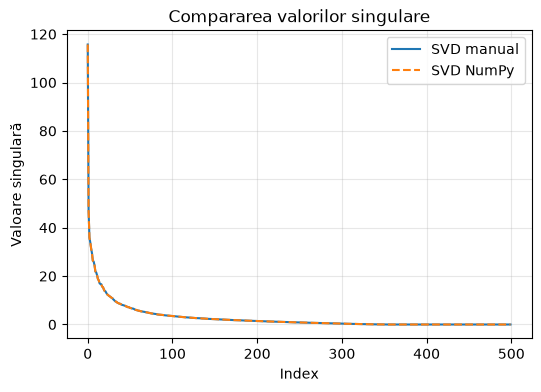

In [8]:

U1, S1, Vt1 = svd_manual(A_test)
U2, S2, Vt2 = np.linalg.svd(A_test, full_matrices=False)

plt.figure(figsize=(6, 4))
plt.plot(S1, label="SVD manual")
plt.plot(S2, label="SVD NumPy", linestyle="--")
plt.title("Compararea valorilor singulare")
plt.xlabel("Index")
plt.ylabel("Valoare singulară")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. Evaluare clasificator: acuratețe și efectul lui k
Testăm clasificatorul Nearest Neighbor în spațiul redus. Apoi repetăm pentru mai multe valori ale lui $k$.


In [9]:

def predict_batch(U_k, train_projections, X_test, y_train):
    preds = []
    for x in X_test:
        idx = solve_cmmp_manual(U_k, train_projections, x)
        preds.append(y_train[idx])
    return np.array(preds, dtype=int)


t0 = time.time()
y_pred = predict_batch(U_k, train_projections, X_test, y_train)
t_pred = time.time() - t0
acc = (y_pred == y_test).mean()
acc, t_pred

(np.float64(0.96), 7.494020223617554)

### 7.1 Matrice de confuzie și exemple de erori


<Figure size 600x600 with 0 Axes>

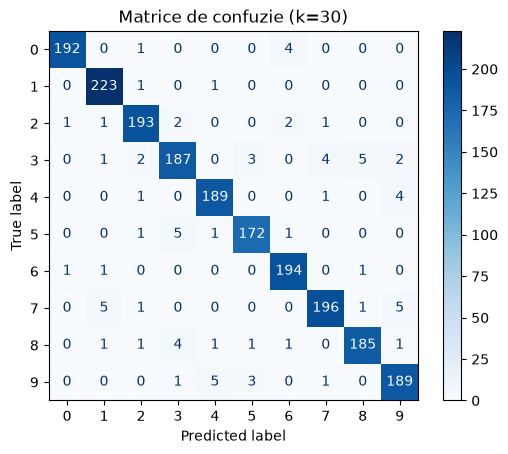

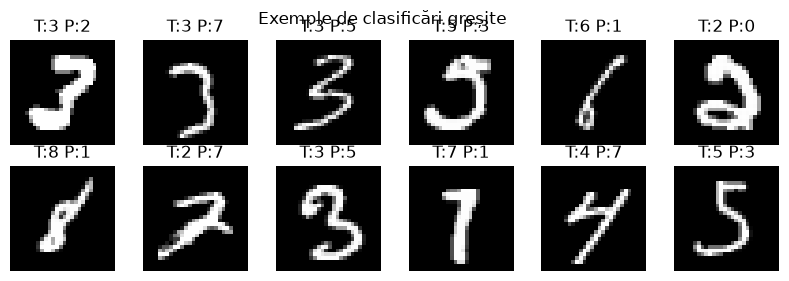

In [10]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=list(range(10)))
plt.figure(figsize=(6, 6))
disp.plot(values_format="d", cmap="Blues")
plt.title("Matrice de confuzie (k=30)")
plt.show()

wrong = np.where(y_pred != y_test)[0][:12]
plt.figure(figsize=(10, 3))
for i, idx in enumerate(wrong):
    plt.subplot(2, 6, i+1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    plt.title(f"T:{y_test[idx]} P:{y_pred[idx]}")
    plt.axis("off")
plt.suptitle("Exemple de clasificări greșite")
plt.show()

### 7.2 Studiu: acuratețe vs k
Tăiem baza $U$ deja calculată (fără să refacem SVD) și evaluăm rapid mai multe valori ale lui k.


In [11]:

k_list = [5, 10, 20, 30, 40, 60, 80, 100]
results = []

for kk in k_list:
    U_kk = U[:, :kk]
    proj_train = U_kk.T @ X_train.T

    t0 = time.time()
    y_pred_kk = predict_batch(U_kk, proj_train, X_test, y_train)
    elapsed = time.time() - t0
    acc_kk = (y_pred_kk == y_test).mean()

    results.append({"k": kk, "accuracy": acc_kk, "test_time_s": elapsed})

df_k = pd.DataFrame(results)
df_k

,k,accuracy,test_time_s
0,5,0.6670,0.608188
1,10,0.8885,0.959152
2,20,0.9445,5.900161
3,30,0.9600,6.845918
4,40,0.9575,9.896105
5,60,0.9560,14.559958
6,80,0.9550,19.306933
7,100,0.9550,22.444078


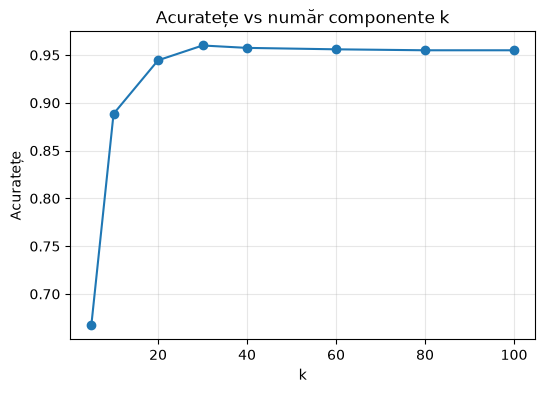

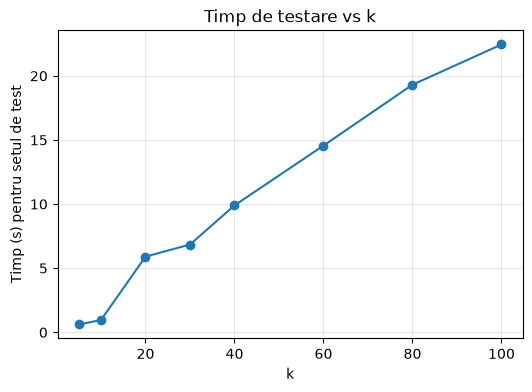

In [12]:

plt.figure(figsize=(6, 4))
plt.plot(df_k["k"], df_k["accuracy"], marker="o")
plt.title("Acuratețe vs număr componente k")
plt.xlabel("k")
plt.ylabel("Acuratețe")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(df_k["k"], df_k["test_time_s"], marker="o")
plt.title("Timp de testare vs k")
plt.xlabel("k")
plt.ylabel("Timp (s) pentru setul de test")
plt.grid(True, alpha=0.3)
plt.show()

## 8. Comparație cu funcții standard: bază obținută cu SVD NumPy
Construim o bază alternativă $U_k$ folosind `numpy.linalg.svd` și comparăm acuratețea.


In [ ]:

print("Construim baza cu NumPy SVD pe același eșantion")
t0 = time.time()
U_np, S_np, Vt_np = np.linalg.svd(X_train[:svd_sample].T, full_matrices=False)
t_svd_np = time.time() - t0

U_k_np = U_np[:, :k]
train_proj_np = U_k_np.T @ X_train.T

t0 = time.time()
y_pred_np = predict_batch(U_k_np, train_proj_np, X_test, y_train)
t_test_np = time.time() - t0
acc_np = (y_pred_np == y_test).mean()

pd.DataFrame([{
    "k": k,
    "svd_time_numpy_s": t_svd_np,
    "test_time_s": t_test_np,
    "accuracy": acc_np
}])

Construim baza cu NumPy SVD pe același eșantion


## 9. Interfață de desen (doar în Google Colab)
Dacă rulezi notebook-ul în Colab, poți desena o cifră într-un canvas și obții predicția.
Dacă rulezi local, această secțiune afișează un mesaj.


In [ ]:

if IN_COLAB:
    def draw_canvas():
        canvas_html = '''
        <div align="center">
          <h3>Desenează o cifră (0-9)</h3>
          <canvas id="myCanvas" width="280" height="280" style="border:2px solid #000; background:black;"></canvas>
          <br>
          <button onclick="predict()" style="padding:10px; margin:10px; background:#4CAF50; color:white;">GHICEȘTE (CMMP)</button>
          <button onclick="clearCanvas()" style="padding:10px; background:#f44336; color:white;">Șterge</button>
        </div>
        <script>
          var canvas = document.getElementById('myCanvas');
          var ctx = canvas.getContext('2d');
          var drawing = false;
          ctx.lineWidth = 18; ctx.lineCap = 'round'; ctx.strokeStyle = "white";

          canvas.addEventListener('mousedown', (e) => { drawing = true; ctx.beginPath(); ctx.moveTo(e.offsetX, e.offsetY); });
          canvas.addEventListener('mousemove', (e) => { if(drawing) { ctx.lineTo(e.offsetX, e.offsetY); ctx.stroke(); } });
          canvas.addEventListener('mouseup', () => drawing = false);

          function clearCanvas() { ctx.fillStyle = "black"; ctx.fillRect(0, 0, canvas.width, canvas.height); }
          function predict() {
            var dataURL = canvas.toDataURL('image/png');
            google.colab.kernel.invokeFunction('notebook.predict_digit', [dataURL], {});
          }
        </script>
        '''
        display(HTML(canvas_html))

    def predict_digit(data_url):
        img_str = data_url.split(',')[1]
        image = Image.open(BytesIO(base64.b64decode(img_str))
                           ).convert('L').resize((28, 28))
        input_vector = np.array(image).flatten() / 255.0

        if np.sum(input_vector) == 0:
            print("Te rugăm să desenezi ceva!")
            return

        start_t = time.time()
        best_match_idx = solve_cmmp_manual(
            U_k, train_projections, input_vector)
        prediction = y_train[best_match_idx]
        end_t = time.time()

        print(
            f"Rezultat Predicție: {prediction} (Calculat în {end_t - start_t:.4f}s)")

        plt.figure(figsize=(2, 2))
        plt.imshow(input_vector.reshape(28, 28), cmap='gray')
        plt.title(f"Predicție: {prediction}")
        plt.axis('off')
        plt.show()

    output.register_callback('notebook.predict_digit', predict_digit)
    draw_canvas()
else:
    print("Nu rulezi în Google Colab; canvas-ul interactiv nu este disponibil aici.")

## 10. Concluzii și comentarii
- **SVD manual** (prin $A^T A$) reproduce bine valorile singulare ale lui NumPy, dar este în general **mai lentă** și mai sensibilă numeric.
- Reducerea dimensională cu $k$ mic accelerează clasificarea, dar dacă $k$ este prea mic, se pierde informație → acuratețe mai mică.
- Pe măsură ce $k$ crește, acuratețea tinde să crească (până la un punct), dar crește și timpul de testare.
- În practică, `numpy.linalg.svd` este recomandată pentru performanță și stabilitate numerică.
